# Phase 2 – Exploratory Data Analysis (EDA)

## IndiaKart E-Commerce

## Objective
The objective of this phase is to explore the cleaned IndiaKart data and find patterns in orders, revenue, categories, customers, payments and returns, using charts with short observations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
dark_color = "#0B3C5D"
light_color = "#4FA3D1"

orders = pd.read_csv("orders_cleaned.csv", parse_dates=["order_date", "delivered_date"])
order_items = pd.read_csv("order_items_cleaned.csv")
customers = pd.read_csv("customers_cleaned.csv", parse_dates=["registration_date", "last_login_date"])
payments = pd.read_csv("payments_cleaned.csv", parse_dates=["payment_date", "refund_date"])
returns = pd.read_csv("returns_cleaned.csv", parse_dates=["return_date", "refund_date"])
products = pd.read_csv("products_cleaned.csv")

for name, df in [("orders", orders), ("order_items", order_items), ("customers", customers),
                 ("payments", payments), ("returns", returns), ("products", products)]:
    print(name, df.shape)

orders (50000, 20)
order_items (100000, 11)
customers (10000, 17)
payments (50000, 13)
returns (10000, 10)
products (1000, 17)


## Chart 1 – Monthly Order Volume

Average orders per full month: 2087
Highest: 2025-01 2239 | Lowest: 2025-02 1879
Oct-Nov average: 2097 | other months average: 2085


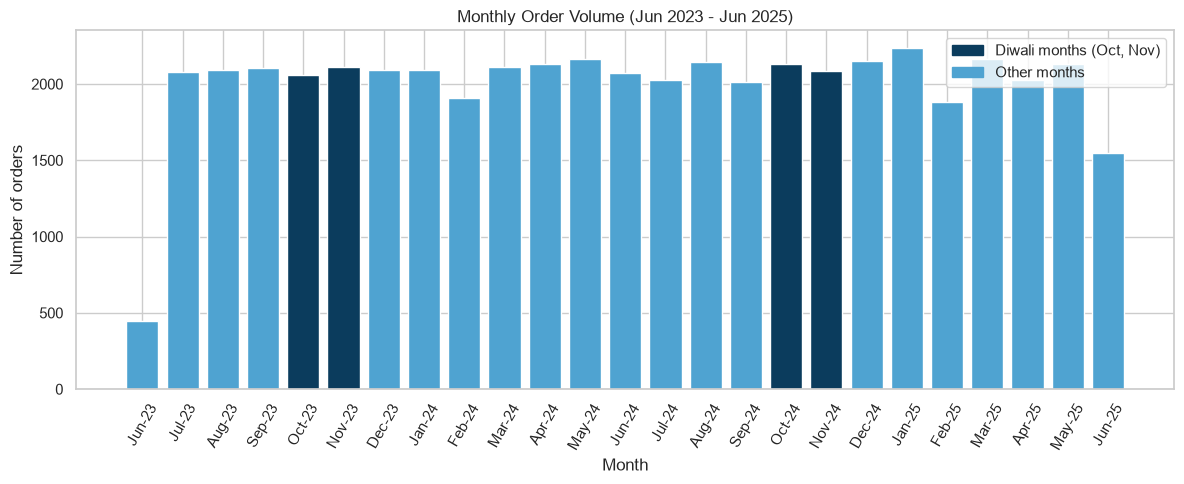

In [2]:
from matplotlib.patches import Patch

orders["month"] = orders["order_date"].dt.to_period("M")
monthly_orders = orders.groupby("month").size()
month_labels = monthly_orders.index.strftime("%b-%y")

# Diwali months (October and November) in the dark color
bar_colors = []
for m in monthly_orders.index:
    if m.month in [10, 11]:
        bar_colors.append(dark_color)
    else:
        bar_colors.append(light_color)

# the first and last month are partial, so leave them out of the averages
full = monthly_orders.iloc[1:-1]
print("Average orders per full month:", round(full.mean()))
print("Highest:", full.idxmax(), full.max(), "| Lowest:", full.idxmin(), full.min())
print("Oct-Nov average:", round(monthly_orders[monthly_orders.index.month.isin([10, 11])].mean()),
      "| other months average:", round(full[~full.index.month.isin([10, 11])].mean()))

plt.figure(figsize=(12, 5))
plt.bar(range(len(monthly_orders)), monthly_orders.values, color=bar_colors)
plt.xticks(range(len(monthly_orders)), month_labels, rotation=60)
plt.title("Monthly Order Volume (Jun 2023 - Jun 2025)")
plt.xlabel("Month")
plt.ylabel("Number of orders")
plt.legend(handles=[Patch(color=dark_color, label="Diwali months (Oct, Nov)"), Patch(color=light_color, label="Other months")])
plt.tight_layout()
plt.savefig("chart1_monthly_orders.png", dpi=150)
plt.show()

### Observation

IndiaKart receives about 2,087 orders in a typical month, and the volume is remarkably steady, ranging from 1,879 (February 2025) to 2,239 (January 2025). The first and last bars (June 2023 and June 2025) are shorter only because the data starts on 24 June 2023 and ends on 23 June 2025. February is the lowest month each year, which is expected as it is the shortest month. There is no visible festive spike: October and November average 2,097 orders, almost the same as the 2,085 of the other months, so the Diwali period does not lift order volume in this data.

## Chart 2 – Monthly Revenue (GMV) by Year

year       2023   2024   2025
month_no                     
1           NaN  13.15  13.79
2           NaN  12.09  11.41
3           NaN  13.37  13.65
4           NaN  13.15  13.08
5           NaN  13.64  13.58
6          2.74  12.37  10.36
7         12.89  12.70    NaN
8         12.81  13.19    NaN
9         13.75  13.05    NaN
10        13.25  13.35    NaN
11        13.73  12.63    NaN
12        13.69  13.31    NaN
Total GMV (Rs crore): 314.74
Year 1 GMV (Rs crore): 157.68 | Year 2: 157.06 | growth %: -0.4


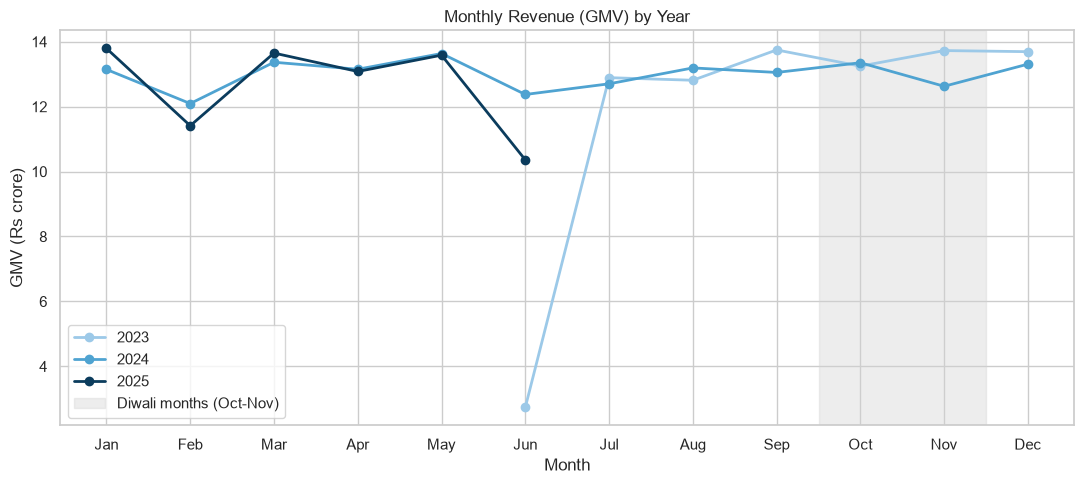

In [3]:
orders["year"] = orders["order_date"].dt.year
orders["month_no"] = orders["order_date"].dt.month

# GMV in Rs crore for every month and year
gmv_pivot = orders.pivot_table(index="month_no", columns="year", values="final_amount", aggfunc="sum") / 10000000
print(gmv_pivot.round(2))
print("Total GMV (Rs crore):", round(orders["final_amount"].sum() / 10000000, 2))

# first year (24 Jun 2023 - 23 Jun 2024) against the second year
year1 = orders[(orders["order_date"] >= "2023-06-24") & (orders["order_date"] < "2024-06-24")]["final_amount"].sum()
year2 = orders[orders["order_date"] >= "2024-06-24"]["final_amount"].sum()
print("Year 1 GMV (Rs crore):", round(year1 / 10000000, 2), "| Year 2:", round(year2 / 10000000, 2),
      "| growth %:", round((year2 / year1 - 1) * 100, 2))

colors = {2023: "#9CC9E8", 2024: light_color, 2025: dark_color}

plt.figure(figsize=(11, 5))
for year in gmv_pivot.columns:
    plt.plot(gmv_pivot.index, gmv_pivot[year], marker="o", linewidth=2, color=colors[year], label=str(year))
plt.axvspan(9.5, 11.5, color="lightgrey", alpha=0.4, label="Diwali months (Oct-Nov)")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.title("Monthly Revenue (GMV) by Year")
plt.xlabel("Month")
plt.ylabel("GMV (Rs crore)")
plt.legend()
plt.tight_layout()
plt.savefig("chart2_monthly_gmv.png", dpi=150)
plt.show()

### Observation

IndiaKart generated about Rs 314.74 crore in GMV over the two years, around Rs 13 crore in a typical month. Revenue is flat year over year: the first year earned Rs 157.68 crore and the second Rs 157.06 crore, a change of -0.4%. The lines for 2023, 2024 and 2025 follow each other closely, and February is the lowest month each year. There is no Diwali boost: October and November 2024 (Rs 25.98 crore combined) were slightly below October and November 2023 (Rs 26.97 crore). The business is stable but not growing, so growth would have to come from new customers or higher order values.

## Chart 3 – Category-wise Revenue Share

Items: 100000 | items in cancelled orders: 12007
                  revenue_crore  share_%
category                                
Electronics              145.46    57.57
Sports & Fitness          43.61    17.26
Home & Kitchen            21.56     8.53
Fashion                   13.12     5.19
Automotive                10.87     4.30
Office Supplies            8.19     3.24
Toys & Baby                4.06     1.61
Beauty & Health            2.92     1.15
Grocery                    1.64     0.65
Books                      1.23     0.49
Total revenue (Rs crore): 252.66
Top 2 categories share: 74.83 %


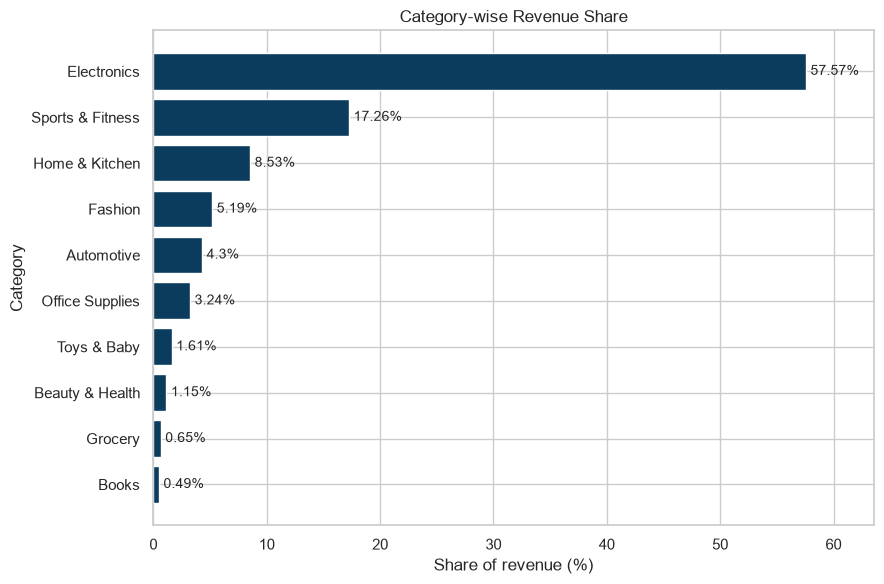

In [4]:
# add the order status to every item, and leave out items from cancelled orders
items = order_items.merge(orders[["order_id", "status"]], on="order_id", how="left")
print("Items:", len(items), "| items in cancelled orders:", (items["status"] == "Cancelled").sum())
items = items[items["status"] != "Cancelled"]

category_revenue = items.groupby("category")["total_price"].sum().sort_values(ascending=False)
category_share = (category_revenue / category_revenue.sum() * 100).round(2)
print(pd.DataFrame({"revenue_crore": (category_revenue / 10000000).round(2), "share_%": category_share}))
print("Total revenue (Rs crore):", round(category_revenue.sum() / 10000000, 2))
print("Top 2 categories share:", category_share.head(2).sum().round(2), "%")

# sort so the biggest bar is at the top
cat_sorted = category_share.sort_values()

plt.figure(figsize=(9, 6))
plt.barh(cat_sorted.index, cat_sorted.values, color=dark_color)
for i in range(len(cat_sorted)):
    plt.text(cat_sorted.values[i] + 0.4, i, str(cat_sorted.values[i]) + "%", va="center", fontsize=10)
plt.xlim(0, cat_sorted.max() + 6)
plt.title("Category-wise Revenue Share")
plt.xlabel("Share of revenue (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("chart3_category_revenue.png", dpi=150)
plt.show()

### Observation

Revenue is highly concentrated: Electronics alone brings in 57.57% of the item revenue (Rs 145.46 crore), and Electronics with Sports & Fitness (17.26%) account for 74.83%. Home & Kitchen is third at 8.53%, and the remaining seven categories share only about 17%. Books (0.49%), Grocery (0.65%) and Beauty & Health (1.15%) contribute very little. IndiaKart therefore depends heavily on electronics, so changes in electronics prices, stock or returns would strongly affect revenue. Revenue here covers orders that have line items and excludes cancelled orders.

## Chart 4 – Order Status Distribution

            orders  percent
status                     
Delivered    32499    65.00
Cancelled     5996    11.99
Shipped       5071    10.14
Returned      3933     7.87
Processing    2501     5.00
Cancelled + Returned: 19.86 %


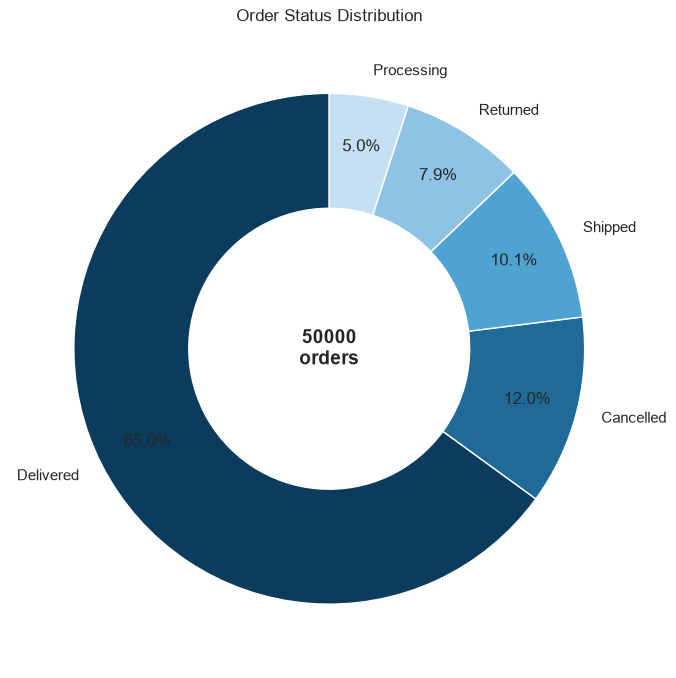

In [5]:
status_counts = orders["status"].value_counts()
status_pct = (status_counts / len(orders) * 100).round(2)
print(pd.DataFrame({"orders": status_counts, "percent": status_pct}))
print("Cancelled + Returned:", round(status_pct["Cancelled"] + status_pct["Returned"], 2), "%")

# five shades of the same blue
blues = ["#0B3C5D", "#1F6A99", "#4FA3D1", "#8EC3E6", "#C5E0F2"]

plt.figure(figsize=(7, 7))
plt.pie(status_counts, labels=status_counts.index, autopct="%1.1f%%", startangle=90, colors=blues,
        pctdistance=0.8, wedgeprops={"width": 0.45, "edgecolor": "white"})
plt.text(0, 0, str(len(orders)) + "\norders", ha="center", va="center", fontsize=14, fontweight="bold")
plt.title("Order Status Distribution")
plt.tight_layout()
plt.savefig("chart4_order_status.png", dpi=150)
plt.show()

### Observation

65.00% of the 50,000 orders were delivered successfully. The other 35% are spread across Cancelled (11.99%), Shipped (10.14%), Returned (7.87%) and Processing (5.00%). Cancelled and Returned orders together make up 19.86%, so about one order in five does not end in a completed sale. Reducing cancellations, which were also linked to the failed payments found in Phase 1, would add revenue directly. The Shipped and Processing orders (15.14%) are still in progress.

## Chart 5 – Top 10 States by Number of Orders

States with orders: 18
                orders  share_%
state                          
Uttar Pradesh     9507    19.01
Maharashtra       8179    16.36
Gujarat           3811     7.62
Madhya Pradesh    3741     7.48
Tamil Nadu        3664     7.33
Karnataka         3102     6.20
Rajasthan         3047     6.09
West Bengal       2103     4.21
Punjab            2073     4.15
Jharkhand         2044     4.09
Top 10 share: 82.54 %
Top 3 share: 42.99 %


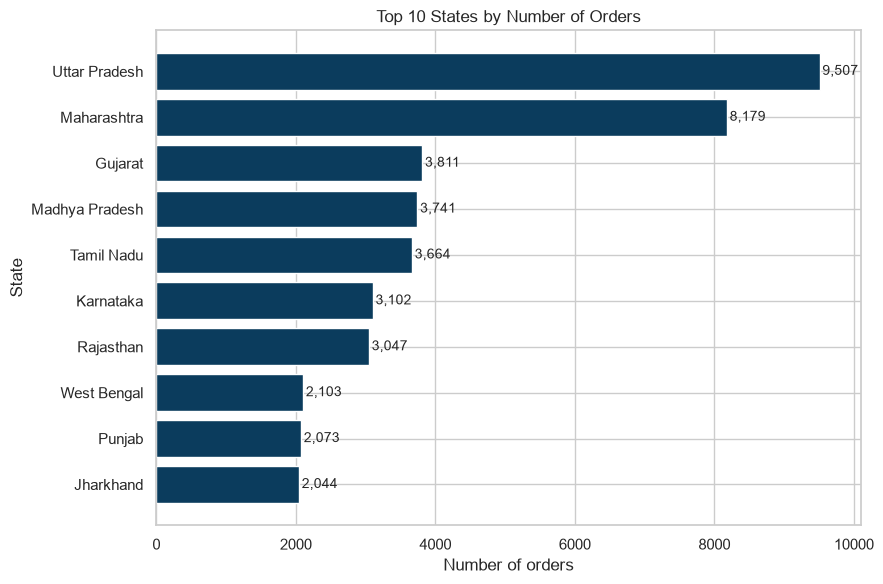

In [6]:
state_orders = orders["state"].value_counts()
print("States with orders:", state_orders.shape[0])

top_states = state_orders.head(10)
print(pd.DataFrame({"orders": top_states, "share_%": (top_states / len(orders) * 100).round(2)}))
print("Top 10 share:", round(top_states.sum() / len(orders) * 100, 2), "%")
print("Top 3 share:", round(top_states.head(3).sum() / len(orders) * 100, 2), "%")

# sort so the biggest bar is at the top
top_sorted = top_states.sort_values()

plt.figure(figsize=(9, 6))
plt.barh(top_sorted.index, top_sorted.values, color=dark_color)
for i in range(len(top_sorted)):
    plt.text(top_sorted.values[i] + 40, i, format(top_sorted.values[i], ","), va="center", fontsize=10)
plt.xlim(0, top_sorted.max() + 600)
plt.title("Top 10 States by Number of Orders")
plt.xlabel("Number of orders")
plt.ylabel("State")
plt.tight_layout()
plt.savefig("chart5_top_states.png", dpi=150)
plt.show()

### Observation

Orders are concentrated in a few states: Uttar Pradesh (9,507 orders, 19.01%) and Maharashtra (8,179 orders, 16.36%) together account for 35% of all orders, and the top 10 states account for 82.54%. After those two, there is a big drop to Gujarat, Madhya Pradesh and Tamil Nadu, which each have around 3,700 orders. Only 18 states have any orders, with Haryana the smallest at 902. IndiaKart's logistics, warehouse capacity and marketing should be strongest in Uttar Pradesh and Maharashtra, while the smaller states are an opportunity for growth.

## Chart 6 – Customer Segment Distribution

          customers  percent
segment                     
Regular        4026    40.26
Budget         2505    25.05
Premium        1501    15.01
New            1488    14.88
Inactive        480     4.80
segment
Regular     46.16
Premium     25.85
Budget      14.55
New         12.91
Inactive     0.54
Name: order_id, dtype: float64


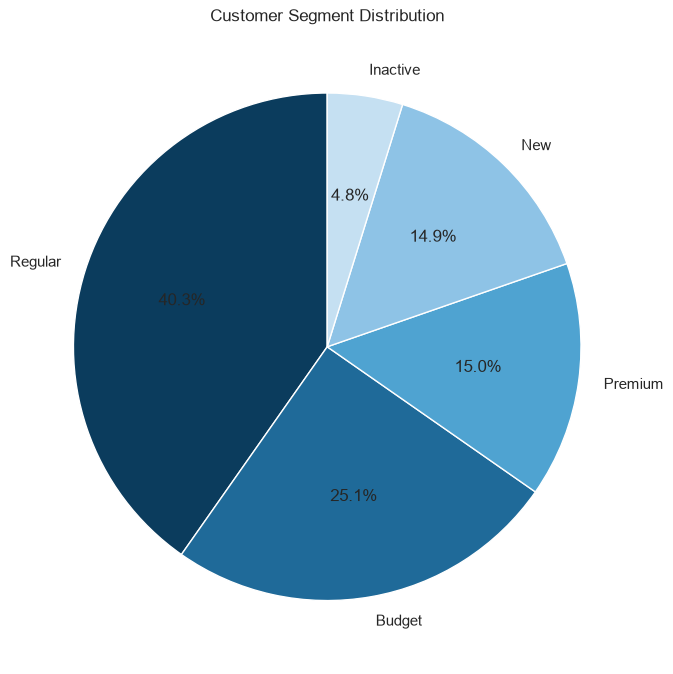

In [7]:
segment_counts = customers["segment"].value_counts()
segment_pct = (segment_counts / len(customers) * 100).round(2)
print(pd.DataFrame({"customers": segment_counts, "percent": segment_pct}))

# how many orders does each segment place?
seg_orders = orders.merge(customers[["customer_id", "segment"]], on="customer_id").groupby("segment")["order_id"].count()
print((seg_orders / len(orders) * 100).round(2).sort_values(ascending=False))

# five shades of the same blue
blues = ["#0B3C5D", "#1F6A99", "#4FA3D1", "#8EC3E6", "#C5E0F2"]

plt.figure(figsize=(7, 7))
plt.pie(segment_counts, labels=segment_counts.index, autopct="%1.1f%%", startangle=90, colors=blues, wedgeprops={"edgecolor": "white"})
plt.title("Customer Segment Distribution")
plt.tight_layout()
plt.savefig("chart6_segments.png", dpi=150)
plt.show()

### Observation

Regular customers are the largest group (40.26% of the 10,000 customers), followed by Budget (25.05%), Premium (15.01%), New (14.88%) and Inactive (4.80%). These shares match the segment mix given in the data dictionary. The most important detail is the difference between customer share and order share: Premium customers are only 15% of the customer base but place 25.85% of all orders, while Budget customers are 25% of customers but place only 14.55% of orders. Premium customers are therefore the most valuable group to retain, and the 480 inactive customers (4.80%), who place only 0.54% of orders, are a chance for re-engagement campaigns.

## Chart 7 – Payment Method Usage

                  payments  share_%  failure_%
payment_method                                
UPI                  17570    35.14       3.55
Credit Card          10007    20.01       3.63
Debit Card            7624    15.25       3.02
Cash on Delivery      5883    11.77       3.55
Net Banking           4026     8.05       3.95
EMI                   2943     5.89       2.96
Wallet                1947     3.89       3.90
Digital (non-COD) share: 88.23 %


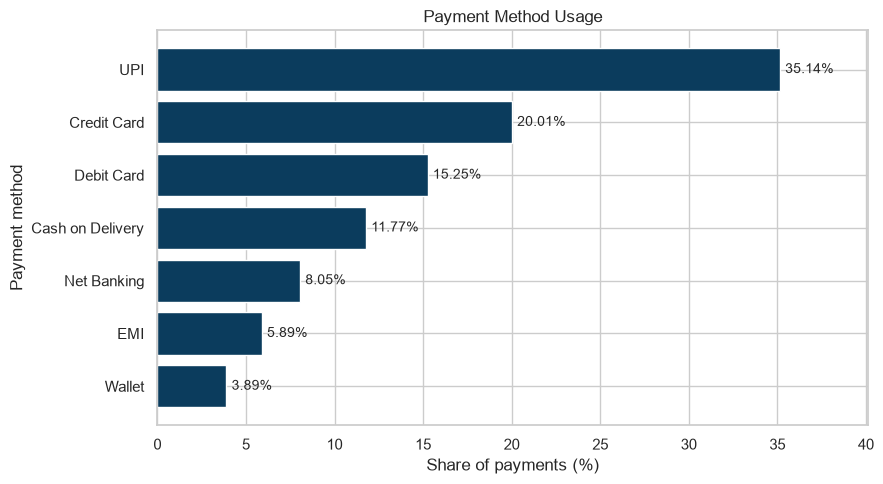

In [8]:
method_counts = payments["payment_method"].value_counts()
method_pct = (method_counts / len(payments) * 100).round(2)

# failure rate of each method
fail_rate = payments.groupby("payment_method")["status"].apply(lambda s: round((s == "Failed").mean() * 100, 2))
print(pd.DataFrame({"payments": method_counts, "share_%": method_pct, "failure_%": fail_rate[method_counts.index]}))
print("Digital (non-COD) share:", round(100 - method_pct["Cash on Delivery"], 2), "%")

# sort so the biggest bar is at the top
m_sorted = method_pct.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(m_sorted.index, m_sorted.values, color=dark_color)
for i in range(len(m_sorted)):
    plt.text(m_sorted.values[i] + 0.3, i, str(m_sorted.values[i]) + "%", va="center", fontsize=10)
plt.xlim(0, m_sorted.max() + 5)
plt.title("Payment Method Usage")
plt.xlabel("Share of payments (%)")
plt.ylabel("Payment method")
plt.tight_layout()
plt.savefig("chart7_payment_methods.png", dpi=150)
plt.show()

### Observation

UPI is the most used payment method (35.14% of the 50,000 payments), followed by credit cards (20.01%) and debit cards (15.25%). Together these three account for 70% of payments. Cash on Delivery is still used for 11.77% of payments, so 88.23% of payments are digital. Failure rates are similar across methods (between 2.96% for EMI and 3.95% for Net Banking), so no single method is responsible for the overall 3.50% failure rate. Net Banking and Wallet have the highest failure rates, and improving their reliability could recover some lost orders.

## Chart 8 – Age Distribution of Customers

count    10000.0
mean        41.7
std         13.8
min         18.0
25%         30.0
50%         42.0
75%         54.0
max         65.0
Name: age, dtype: float64
Ages outside 18-100: 0
age
18-25    16.28
26-35    20.74
36-45    21.22
46-55    20.26
56+      21.50
Name: proportion, dtype: float64


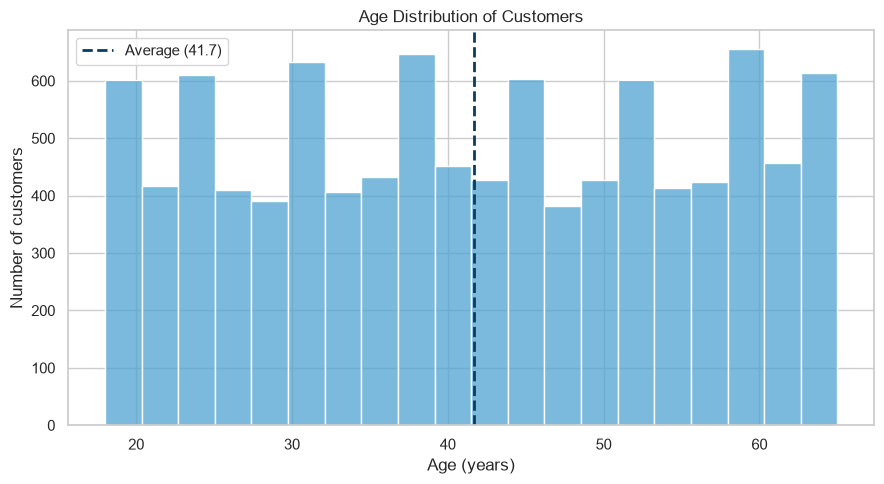

In [9]:
print(customers["age"].describe().round(1))
print("Ages outside 18-100:", ((customers["age"] < 18) | (customers["age"] > 100)).sum())

# share of customers in each age group
bands = pd.cut(customers["age"], bins=[17, 25, 35, 45, 55, 100], labels=["18-25", "26-35", "36-45", "46-55", "56+"])
print((bands.value_counts(normalize=True).sort_index() * 100).round(2))

plt.figure(figsize=(9, 5))
sns.histplot(customers["age"], bins=20, color=light_color, edgecolor="white")
plt.axvline(customers["age"].mean(), color=dark_color, linestyle="--", linewidth=2, label="Average (" + str(round(customers["age"].mean(), 1)) + ")")
plt.title("Age Distribution of Customers")
plt.xlabel("Age (years)")
plt.ylabel("Number of customers")
plt.legend()
plt.tight_layout()
plt.savefig("chart8_age.png", dpi=150)
plt.show()

### Observation

Customers are aged between 18 and 65, with an average of 41.7 years and a median of 42. The distribution is almost flat: each age group from 26 to 65 holds about 20% to 21% of customers, and the 18-25 group is slightly smaller (16.28%) because it covers fewer years. There is no single dominant age group, and no unrealistic ages were found. This means IndiaKart serves a broad adult audience, so marketing does not need to focus on one age group, and the 56+ group (21.5%) is a significant customer base that online retailers often overlook.

## Chart 9 – Return Reasons

                         returns  share_%
reason                                   
Size Issue                  1196    11.96
Changed Mind                1150    11.50
Damaged in Transit          1143    11.43
Wrong Product Delivered     1135    11.35
Defective Product           1134    11.34
Not as Described            1125    11.25
Duplicate Order             1081    10.81
Quality Issue               1075    10.75
Delayed Delivery             484     4.84
Better Price Found           477     4.77
Product or delivery-condition reasons: 56.12 %


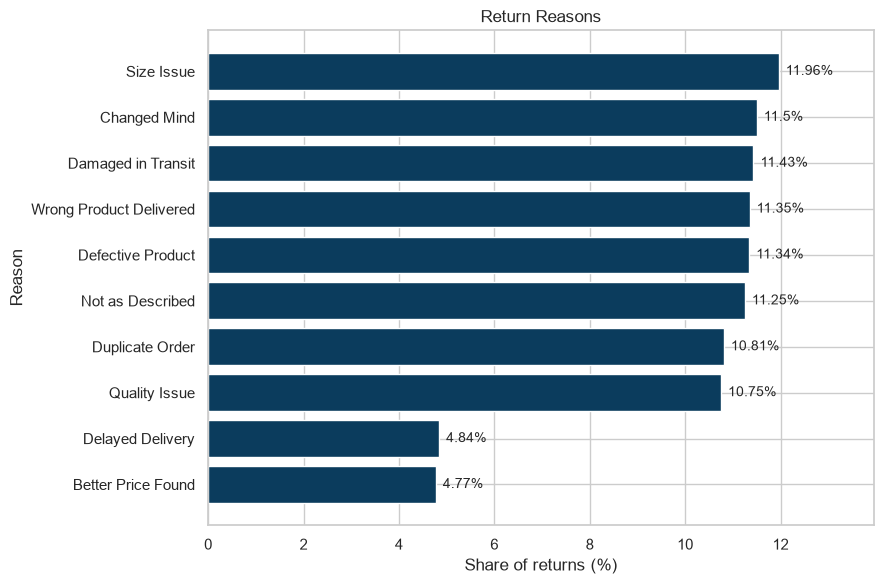

In [10]:
reason_counts = returns["reason"].value_counts()
reason_pct = (reason_counts / len(returns) * 100).round(2)
print(pd.DataFrame({"returns": reason_counts, "share_%": reason_pct}))

quality_reasons = ["Defective Product", "Damaged in Transit", "Quality Issue", "Not as Described", "Wrong Product Delivered"]
print("Product or delivery-condition reasons:", reason_pct[quality_reasons].sum().round(2), "%")

# sort so the biggest bar is at the top
r_sorted = reason_pct.sort_values()

plt.figure(figsize=(9, 6))
plt.barh(r_sorted.index, r_sorted.values, color=dark_color)
for i in range(len(r_sorted)):
    plt.text(r_sorted.values[i] + 0.15, i, str(r_sorted.values[i]) + "%", va="center", fontsize=10)
plt.xlim(0, r_sorted.max() + 2)
plt.title("Return Reasons")
plt.xlabel("Share of returns (%)")
plt.ylabel("Reason")
plt.tight_layout()
plt.savefig("chart9_return_reasons.png", dpi=150)
plt.show()

### Observation

Return reasons are spread almost evenly across eight causes, each between 10.75% and 11.96%, with Size Issue the most common (11.96%). Only Delayed Delivery (4.84%) and Better Price Found (4.77%) are clearly less common. The five reasons linked to the product or how it arrived (Damaged in Transit, Wrong Product Delivered, Defective Product, Not as Described and Quality Issue) together make up 56.12% of returns, so more than half of returns could be reduced by better quality checks, careful packing and accurate listings. The even spread also means there is no single quick fix: improving size guides, product descriptions and packaging would each help.

## Chart 10 – Average Order Value (AOV) by Customer Segment

segment
Budget      64951.0
Inactive    63639.0
Regular     63458.0
New         63278.0
Premium     61692.0
Name: final_amount, dtype: float64
Overall AOV: Rs 63198
Delivered orders by segment: {'Regular': 15050, 'Premium': 8375, 'Budget': 4718, 'New': 4175, 'Inactive': 181}


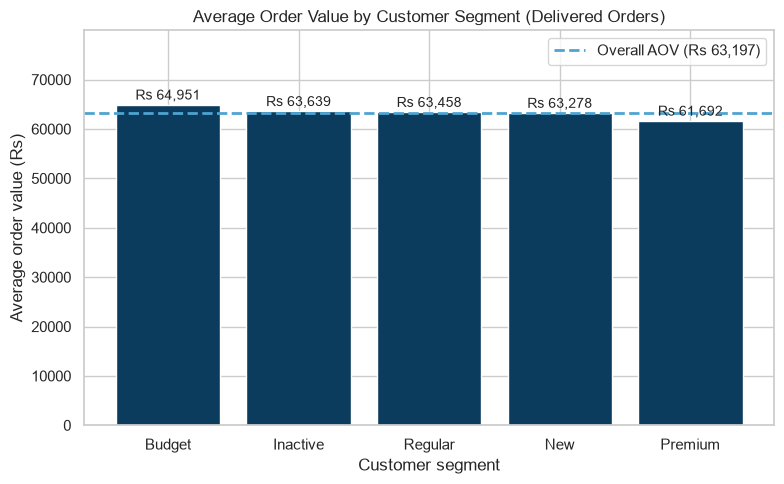

In [11]:
# AOV uses delivered orders only
delivered = orders[orders["status"] == "Delivered"]
data = delivered.merge(customers[["customer_id", "segment"]], on="customer_id", how="left")

aov = data.groupby("segment")["final_amount"].mean().round(0).sort_values(ascending=False)
overall_aov = delivered["final_amount"].mean()
print(aov)
print("Overall AOV: Rs", round(overall_aov))
print("Delivered orders by segment:", data["segment"].value_counts().to_dict())

plt.figure(figsize=(8, 5))
plt.bar(aov.index, aov.values, color=dark_color)
for i in range(len(aov)):
    plt.text(i, aov.values[i] + 1000, "Rs " + format(int(aov.values[i]), ","), ha="center", fontsize=10)
plt.axhline(overall_aov, color=light_color, linestyle="--", linewidth=2, label="Overall AOV (Rs " + format(int(overall_aov), ",") + ")")
plt.ylim(0, aov.max() + 15000)
plt.title("Average Order Value by Customer Segment (Delivered Orders)")
plt.xlabel("Customer segment")
plt.ylabel("Average order value (Rs)")
plt.legend()
plt.tight_layout()
plt.savefig("chart10_aov_by_segment.png", dpi=150)
plt.show()

### Observation

The average order value is very similar across all segments, between Rs 61,692 and Rs 64,951, with an overall AOV of Rs 63,198. Contrary to what one might expect, Premium customers do not spend more per order: their AOV is the lowest (about 2.4% below the average), and Budget customers' is the highest. Premium customers are valuable because they order more often, as Chart 6 showed (15% of customers but 25.85% of orders), and not because each order is larger. To raise revenue per order, IndiaKart should use bundles and add-on offers for all segments, and to grow Premium revenue it should keep those customers ordering frequently.

## Key Insights

**Orders and revenue**
- IndiaKart receives about 2,087 orders and roughly Rs 13 crore in GMV in a typical month, and both are remarkably steady. Total GMV over the two years is Rs 314.74 crore.
- Revenue is flat year over year: Rs 157.68 crore in the first year and Rs 157.06 crore in the second (-0.4%). The business is stable but not growing.
- There is no festive boost: October and November average 2,097 orders, almost the same as the 2,085 of other months.

**Products and categories**
- Revenue is concentrated: Electronics brings in 57.57% of item revenue, and Electronics with Sports & Fitness account for 74.83%.
- Books (0.49%), Grocery (0.65%) and Beauty & Health (1.15%) contribute very little.

**Customers and geography**
- Uttar Pradesh (19.01%) and Maharashtra (16.36%) together produce 35% of all orders, and the top 10 states produce 82.54%.
- Regular customers are 40.26% of the base, but Premium customers (15.01%) place 25.85% of all orders. The 480 inactive customers place only 0.54%.
- Customers are aged 18 to 65 with a flat age spread (average 41.7), so no single age group dominates.
- Average order value is almost the same for every segment (Rs 61,692 to Rs 64,951). Premium customers are valuable because they order often, not because each order is larger.

**Orders, payments and returns**
- Only 65.00% of orders were delivered. Cancelled (11.99%) and Returned (7.87%) orders together make up 19.86%.
- UPI (35.14%), credit cards (20.01%) and debit cards (15.25%) cover 70% of payments, and 88.23% of payments are digital. Failure rates are similar for all methods (2.96% to 3.95%).
- Return reasons are spread evenly. Five product or delivery-condition reasons (damaged in transit, wrong product, defective, not as described and quality issue) make up 56.12% of returns.

**What to focus on**
1. Find new sources of growth, because revenue is flat: new customers, more frequent orders for Premium customers, and the under-used categories.
2. Reduce the concentration risk in Electronics and in two states.
3. Cut cancellations and failed payments, which lose about one order in five before delivery.
4. Improve quality checks, packaging and product descriptions to